In [17]:
import pandas as pd
import mdocfile
from pathlib import Path
import matplotlib.pyplot as plt

In [7]:
tilt_quality = pd.read_csv('/home/gouauxlab/andecath/aretomo_czi_processing_origbin/TiltSeries_Metrics.csv')

In [8]:
raw_data_dir = Path("/goliath/rawdata/Gouaux/CJS/BestTomo/15F1_tomograms/20250204_CZI/25feb24b/25feb24b")

In [ ]:
tilt_quality['Tilt_Series']

In [ ]:
# Add multiple columns to tilt_quality by running a function for every row
def get_mdoc_path(row):
    mdoc_path = (raw_data_dir / row['Tilt_Series']).with_suffix('.mdoc')
    return mdoc_path

tilt_quality['mdoc_path'] = tilt_quality.apply(get_mdoc_info, axis=1)

In [23]:
def get_stage_x(row):
    mdoc = mdocfile.read(row['mdoc_path'])
    return mdoc['StagePosition'][0][0]
tilt_quality['stage_x'] = tilt_quality.apply(get_stage_x, axis=1)

In [24]:
def get_stage_y(row):
    mdoc = mdocfile.read(row['mdoc_path'])
    return mdoc['StagePosition'][0][1]
tilt_quality['stage_y'] = tilt_quality.apply(get_stage_y, axis=1)

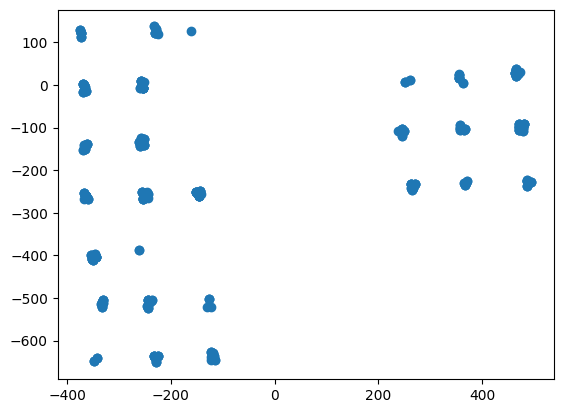

In [26]:
plt.plot(tilt_quality['stage_x'], tilt_quality['stage_y'], 'o')

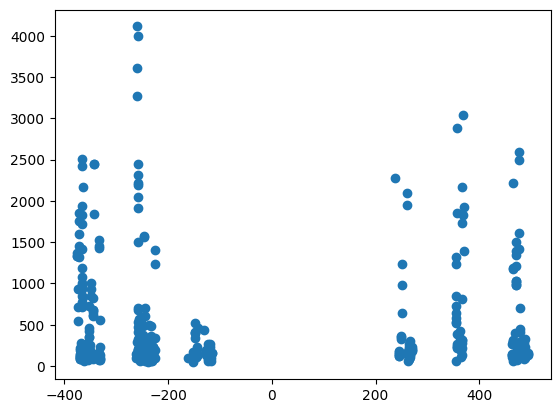

In [28]:
plt.plot(tilt_quality['stage_x'], tilt_quality['Global_Shift(Pix)'], 'o')

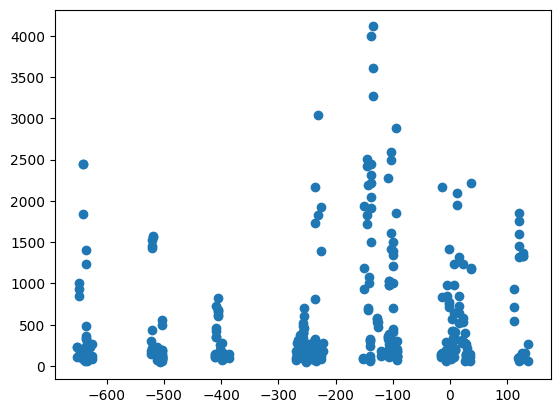

In [29]:
plt.plot(tilt_quality['stage_y'], tilt_quality['Global_Shift(Pix)'], 'o')

In [27]:
# Get columns of tilt_quality
tilt_quality.columns

Index(['Tilt_Series', 'Thickness(Pix)', 'Tilt_Axis', 'Global_Shift(Pix)',
       'Bad_Patch_Low', 'Bad_Patch_All', 'CTF_Res(A)', 'CTF_Score', 'DF_Hand',
       'Pix_Size(A)', 'Cs(nm)', 'Kv', 'Alpha0', 'Beta0', 'mdoc_path',
       'stage_x', 'stage_y'],
      dtype='object')

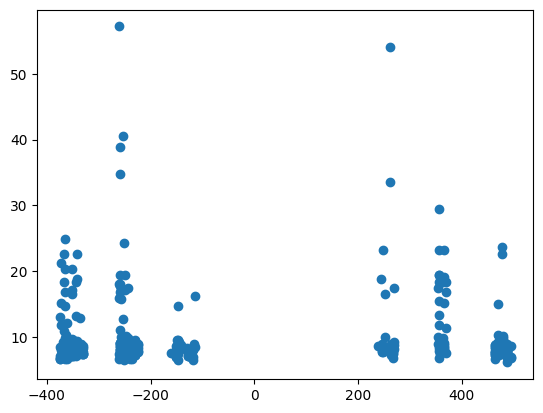

In [34]:
plt.plot(tilt_quality['stage_x'], tilt_quality['CTF_Res(A)'], 'o')

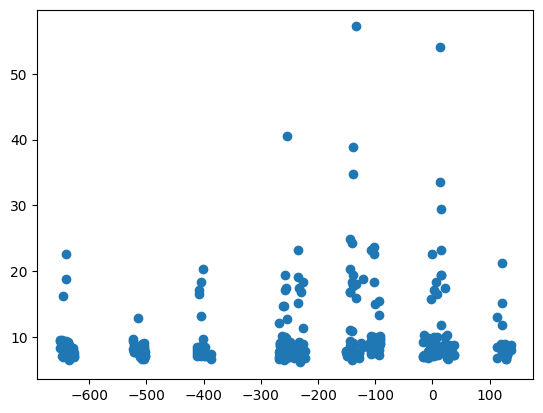

In [35]:
plt.plot(tilt_quality['stage_y'], tilt_quality['CTF_Res(A)'], 'o')

In [36]:
tilt_quality['distance_from_center'] = ((tilt_quality['stage_x'])**2 + (tilt_quality['stage_y'])**2)**0.5

Text(0, 0.5, 'CTF Resolution (A)')

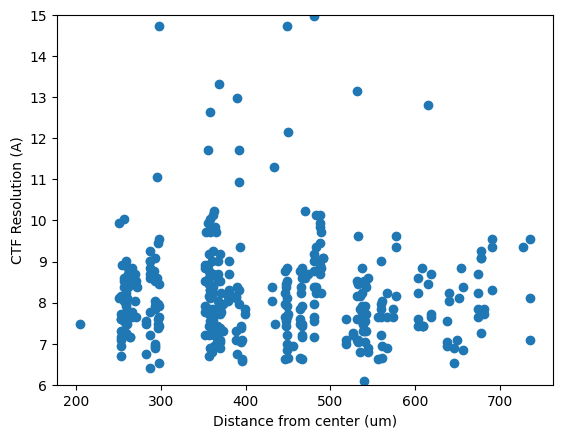

In [40]:
plt.plot(tilt_quality['distance_from_center'], tilt_quality['CTF_Res(A)'], 'o')
plt.ylim(6, 15)
plt.xlabel('Distance from center (um)')
plt.ylabel('CTF Resolution (A)')

(0.0, 500.0)

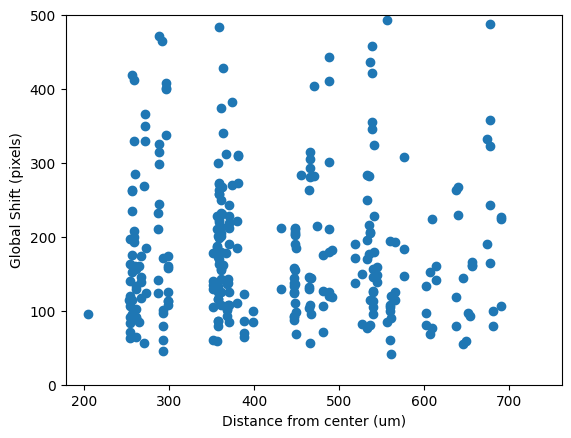

In [42]:
plt.plot(tilt_quality['distance_from_center'], tilt_quality['Global_Shift(Pix)'], 'o')
plt.xlabel('Distance from center (um)')
plt.ylabel('Global Shift (pixels)')
plt.ylim(0, 500)